In [1]:
import pandas as pd
import glob
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler 
from scipy.fft import fft, ifft, fftfreq
import matplotlib.pyplot as plt

In [ ]:
#checking out the pca'd light curves

In [2]:
#let's check them out
final_df = pd.read_csv('/home/3155/best_cands_no_0029')

In [33]:
final_df['filename'][0][-5:-1]

'0016'

In [83]:
def get_tot_denoised(df, i, cut=True):
    filename = 'lightcurve_'+df.loc[i, 'filename'][:-5]+'0000_'+str(df.loc[i, 'quad'])+'_'+f'{int(df.loc[i,"closest_x"]):04}'+'_'+f'{int(df.loc[i,"closest_y"]):04}'+'_time_adjusted_concat_denoised'
    print(filename)
    anarray = pd.read_csv('/lustre/lrspec/ZTF_data/lightcurves/1020_time_concat_denoised/'+filename, header=None).values.flatten()
    if cut==False:
        return anarray
    else:
        number = int(df.loc[i, 'filename'][-5:-1])
        num = 1
        return anarray[num*3080:(num+1)*3080] #possibly one pixel off but should be close enough for SNR

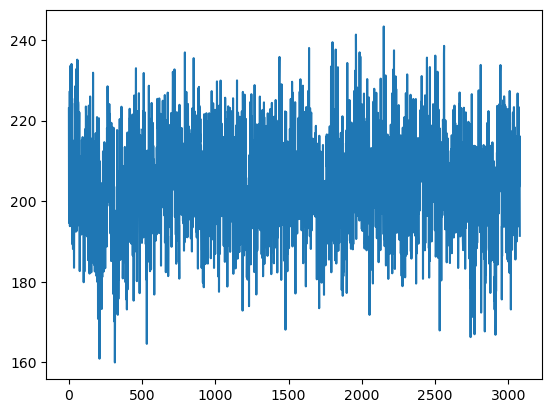

In [45]:
plt.plot(get_tot_denoised(final_df,3,cut=True))

In [2]:
def original_rows_to_array(original):
    # array = np.zeros((20,20))
    cleaned = original[1:-1]
    
    # Split into rows
    rows = []
    current_row = []
    
    # Split by brackets to identify rows
    parts = cleaned.strip().split(' ')
    # print(parts)
    real = []
    for part in parts:
        if part!='':
            correct = float(part)
            real.append(correct)
    
    real = np.array(real)
    
    return np.array(real)

In [ ]:
import review_findings_functions as rff

In [90]:
def add_snr_both_denoised(olddf, lcfpath='/lustre/lrspec/ZTF_data/lightcurves/1020/'):
    '''
    add pos and neg integrated snrs
    returns the dataframe with new columns for outputs of
    snr_local, snr_global, noise_local, noise_global, local_average_outside, height, FWHM, brightest/dimmest row 
    currently hardcoded half ap = 2
    '''
    wid=10
    df = olddf.copy()
    column_names_brightening = ['snr_local_brightening', 'snr_global_brightening', 'noise_local_brightening', 'noise_global_brightening', 
                'local_average_outside_brightening', 'height_brightening', 'FWHM_brightening', 'signal_local_brightening', 'central_point_brightening']
    column_names_dimming = ['snr_local_dimming', 'snr_global_dimming', 'noise_local_dimming', 'noise_global_dimming', 
                'local_average_outside_dimming', 'height_dimming', 'FWHM_dimming', 'signal_local_dimming', 'central_point_dimming']
    for i, name in enumerate(column_names_dimming):
        column_names_dimming[i]=name+'_denoised'
    column_names_brightening = np.array(column_names_brightening)
    for i, name in enumerate(column_names_brightening):
        column_names_brightening[i]=name+'_denoised'
        
    for col in column_names_brightening:
        df[col] = np.zeros(len(df))
    for col in column_names_dimming:
        df[col] = np.zeros(len(df))
    for filename, filenamegroup in df.groupby('filename'):  
        for quad, quadgroup in filenamegroup.groupby('quad'):
            for closest_x, closest_xgroup in quadgroup.groupby('closest_x'): #which light curve it is
                
                try:
                    tot = get_tot_denoised(df, closest_xgroup.index[0]) #will be the same for all so just using the first
                
                    for index in closest_xgroup.index:
                        # row = int(df.loc[index, "row_from_nn"]) + wid
                        # print(df.loc[index, "original_rows_from_nn"].type)
                        if type(df.loc[index, "original_rows_from_nn"] )==str:
                            aggrows = original_rows_to_array(df.loc[index, "original_rows_from_nn"]) + wid
                        else:
                            aggrows = df.loc[index, "original_rows_from_nn"] + wid
                        #first brightening
                        print(tot)
                        print(aggrows)
                        snr_local, snr_global, noise_local, noise_global, local_average_outside, height, FWHM, signal_local, tallest_index_absolute = rff.get_snr_brightest(tot, aggrows)                    
                        df.loc[index, column_names_brightening] = [snr_local, snr_global, noise_local, noise_global, local_average_outside, height, FWHM, signal_local, tallest_index_absolute]
                        #now dimming
                        snr_local, snr_global, noise_local, noise_global, local_average_outside, height, FWHM, signal_local, tallest_index_absolute = rff.get_snr_dimmest(tot, aggrows)                    
                        df.loc[index, column_names_dimming] = [snr_local, snr_global, noise_local, noise_global, local_average_outside, height, FWHM, signal_local, tallest_index_absolute]
                except:
                    print("didn't work: ", filename)
                
    return df

In [92]:
np.sum(df['local_average_outside_dimming_denoised'])

46642.5342859171

In [88]:
df = add_snr_both_denoised(final_df[final_df['filename']=='ztf_20221020141806_000686_zi_c01_x_0028.'])

lightcurve_ztf_20221020141806_000686_zi_c01_x_0000_1_0454_2061_time_adjusted_concat_denoised
[875.3114329  895.09275025 887.53812773 ... 862.92858904 845.04692003
 826.93014853]
[1071.5]


In [91]:
df = add_snr_both_denoised(final_df)

lightcurve_ztf_20221020138241_000686_zi_c04_x_0000_2_2614_1235_time_adjusted_concat_denoised
didn't work:  ztf_20221020138241_000686_zi_c04_x_0001.
lightcurve_ztf_20221020138241_000686_zi_c04_x_0000_2_2877_1080_time_adjusted_concat_denoised
didn't work:  ztf_20221020138241_000686_zi_c04_x_0022.
lightcurve_ztf_20221020138241_000686_zi_c16_x_0000_4_2557_1131_time_adjusted_concat_denoised
[210.27632631 224.5920101  230.00690356 ... 219.54577432 239.31994048
 208.50096301]
[2890.         2911.85714286 2901.07142857]
lightcurve_ztf_20221020138241_000686_zi_c16_x_0000_1_0911_2074_time_adjusted_concat_denoised
[285.01666814 258.82889828 266.44334521 ... 268.2806276  247.87108899
 272.16759617]
[1156.2]
lightcurve_ztf_20221020138241_000686_zi_c16_x_0000_3_0759_0193_time_adjusted_concat_denoised
[273.764542   299.27124246 279.84691354 ... 255.64508339 268.73696103
 261.67795879]
[713.33333333]
lightcurve_ztf_20221020141806_000686_zi_c01_x_0000_1_1266_0100_time_adjusted_concat_denoised
[358.3047

In [ ]:
#let's get the SNRs from the new filtered lcs

In [2]:
df = pd.read_csv('/lustre/lrspec/ZTF_data/lightcurves/1020_time_concat_denoised/lightcurve_ztf_20221020141806_000686_zi_c01_x_0000_1_0454_2061_time_adjusted_concat_denoised', header=None)

In [94]:
local_or_global='local'
for i, row in df.iterrows():
    if row['real_type_'+local_or_global]=='pos':
        df.loc[i, 'snr_local_denoised'] = df.loc[i, 'snr_local_brightening_denoised']
    else:
        df.loc[i, 'snr_local_denoised'] = df.loc[i, 'snr_local_dimming_denoised']


In [127]:
%matplotlib inline

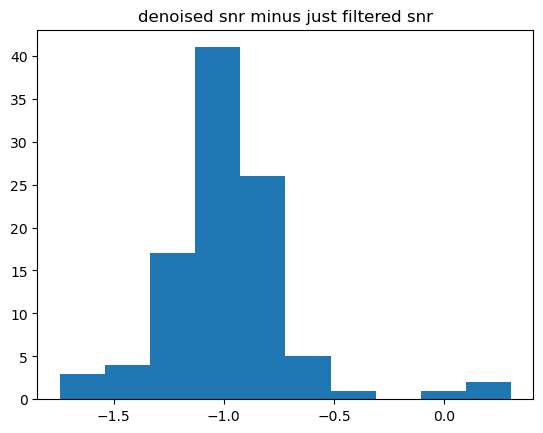

In [110]:
plt.hist(df['snr_local_denoised'].values-df['snr_local_filtered2'].values)
plt.title('denoised snr minus just filtered snr')
plt.show()


Text(0.5, 1.0, 'top candidates by snr_filtered')

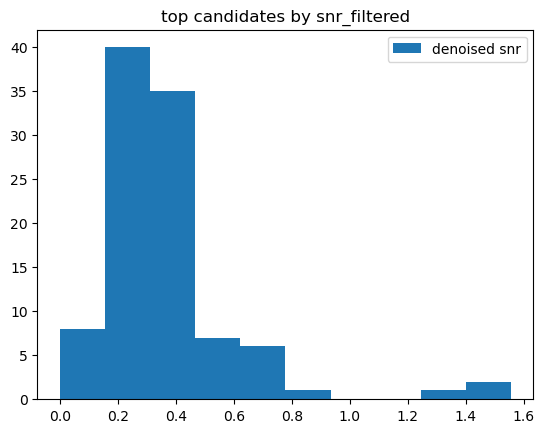

In [116]:
plt.hist(df['snr_local_denoised'].values, label='denoised snr')
plt.legend()
# plt.title('denoised snr minus just filtered snr')
plt.title('top candidates by snr_filtered')

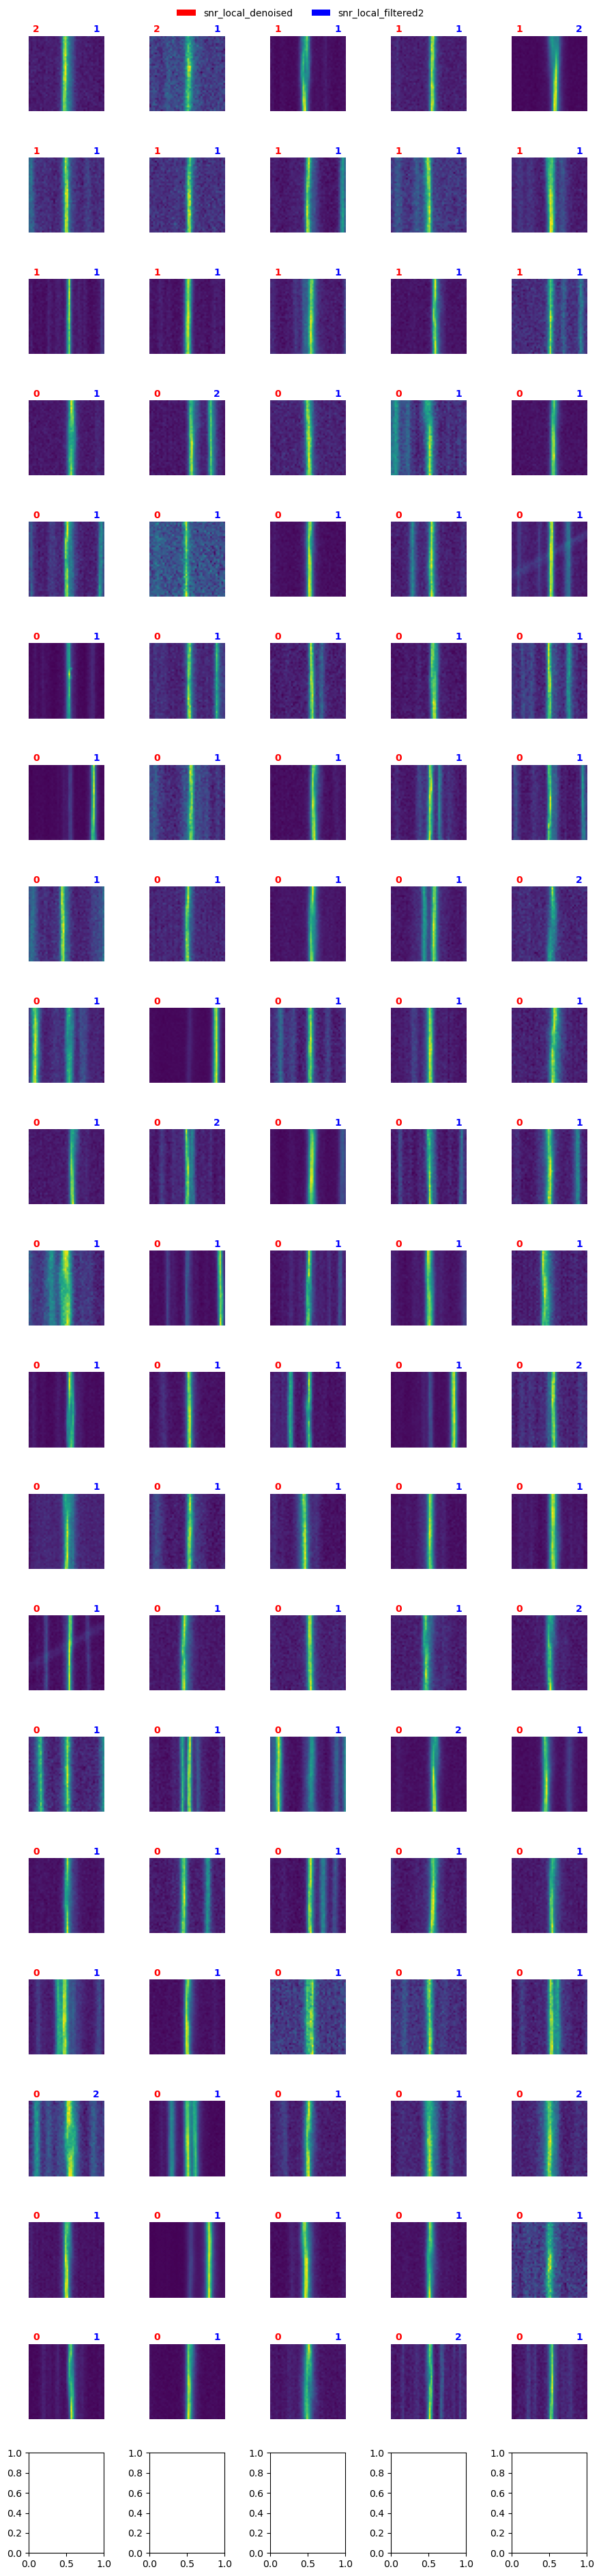

In [115]:
rff.inspect_df_w_stamp_color(df.sort_values('snr_local_denoised', ascending=False), 
                             titlecol=['snr_local_denoised', 'snr_local_filtered2'], imgsize=20)

In [119]:
df_final = df

In [122]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

lightcurve_ztf_20221020294271_000449_zr_c14_x_0000_3_0241_2844_time_adjusted_concat_denoised
lightcurve_ztf_20221020148032_000686_zg_c03_x_0000_3_0223_1462_time_adjusted_concat_denoised
lightcurve_ztf_20221020141806_000686_zi_c01_x_0000_2_1138_0484_time_adjusted_concat_denoised
lightcurve_ztf_20221020297847_000449_zr_c16_x_0000_4_1099_1476_time_adjusted_concat_denoised
lightcurve_ztf_20221020297847_000449_zr_c14_x_0000_4_0374_0759_time_adjusted_concat_denoised
lightcurve_ztf_20221020138241_000686_zi_c16_x_0000_4_2557_1131_time_adjusted_concat_denoised
lightcurve_ztf_20221020148032_000686_zg_c16_x_0000_1_2139_1558_time_adjusted_concat_denoised
lightcurve_ztf_20221020297847_000449_zr_c09_x_0000_2_3047_0513_time_adjusted_concat_denoised
lightcurve_ztf_20221020294271_000449_zr_c16_x_0000_4_0536_1931_time_adjusted_concat_denoised
lightcurve_ztf_20221020138241_000686_zi_c04_x_0000_2_2877_1080_time_adjusted_concat_denoised
couldnt get tot denoised


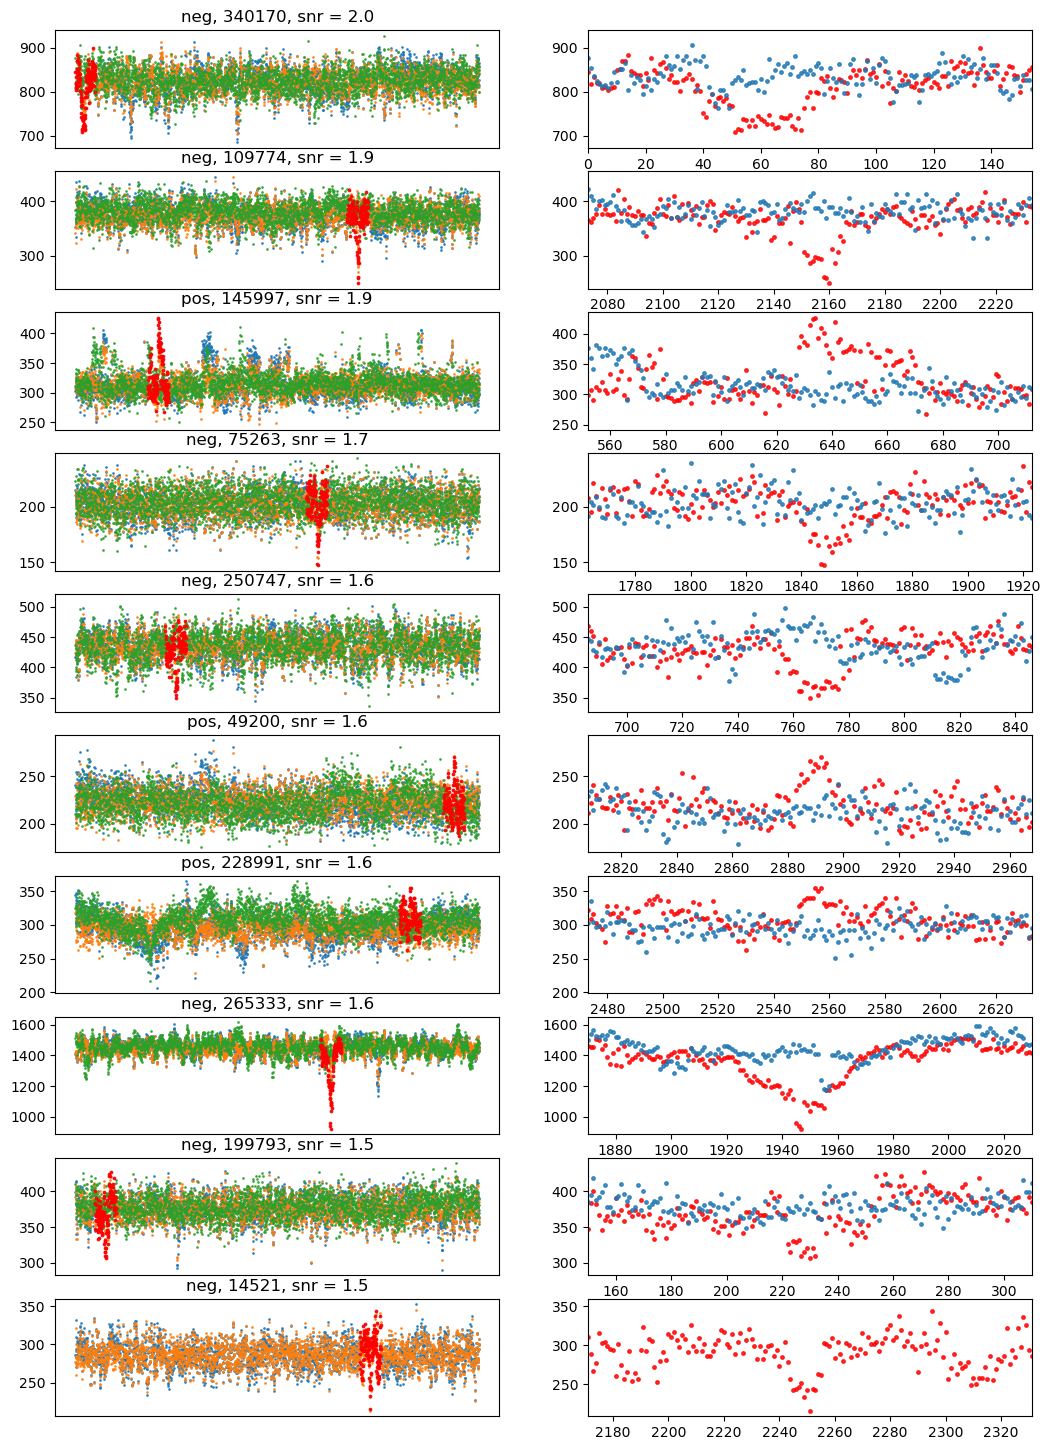

In [132]:
size = 160
# new = final_df_rfgood_filtered.loc[indices_to_plot]
# df = final_df_rfgood_filtered.loc[indices_to_plot]
df = df_final[:10]
figrows = len(df)
fig, ax = plt.subplots(figrows, 2, figsize=(7 * 1.8, figrows * 1.8))

for i, index in enumerate(df.index[:figrows].values):
    # print(index)
    tot, maxols = rff.get_tot_csv(df, index)
    ax[i,0].plot(tot, '.', ms=2, alpha=.8)
    tot_filt = rff.get_tot_csv_filtered_hap2(df, index)
    ax[i,0].plot(tot_filt, '.', ms=2, alpha=.8)
    ax[i,0].set_title(str(df.loc[index, "real_type_local"])+", "+str(df.loc[index, "concat_index_copy"])+", snr = "+f"{df.loc[index, 'snr_local_filtered2']:.1f}")
    ax[i,0].set_xticks([])
    ax[i,1].plot(tot, '.', ms=5, alpha=.8, c='red')
    
    try:
        if str(df.loc[index, "real_type_local"])=='pos':
            range1 = np.max([int(df.loc[index, 'central_point_brightening_filtere']-size//2), 0])
            range2 = np.min([int(df.loc[index, 'central_point_brightening_filtere']+size//2-1), len(tot)])
            xes = np.linspace(range1, range2, range2-range1+1)
            # print(range1, range2, len(tot), len(tot[range1:range2+1]))
            # print(len(xes))
            # print(xes)
            ax[i,1].set_xlim(range1, range2+1)
            ax[i,0].scatter(xes,tot[range1:range2+1],  s=3, alpha=.8, c='red', zorder=10)
        elif str(df.loc[index, "real_type_local"])=='neg':
            
            range1 = np.max([int(df.loc[index, 'central_point_dimming_filtere']-size//2), 0])
            range2 = np.min([int(df.loc[index, 'central_point_dimming_filtere']+size//2-1), len(tot)])
            # print(range1, range2, len(tot), len(tot[range1:range2+1]), len(xes))
            xes = np.linspace(range1, range2, range2-range1+1)
            # print(len(xes))
            # print(xes)
            ax[i,1].set_xlim(range1, range2+1)
            ax[i,0].scatter(xes,tot[range1:range2+1],  s=3, alpha=.8, c='red', zorder=10)
            
            # xes = np.linspace(df.loc[index, 'central_point_dimming_filtere']-size//2,df.loc[index, 'central_point_dimming_filtere']+size//2-1,2*(size//2))
            # # print(len(xes))
            # # print(xes)
            # ax[i,1].set_xlim(df.loc[index, 'central_point_dimming_filtere']-size//2, df.loc[index, 'central_point_dimming_filtere']+size//2)
            # ax[i,0].scatter(xes,tot[int(df.loc[index, 'central_point_dimming_filtere'])-size//2:int(df.loc[index, 'central_point_dimming_filtere'])+size//2],  s=15, alpha=.8, c='red', zorder=10)
    except TypeError:
        pass
    try:
        tot_denoised = rff.get_tot_denoised(df, index)
        ax[i,0].plot(tot_denoised, '.', ms=2, alpha=.8)
        ax[i,1].plot(tot_denoised, '.', ms=5, alpha=.8)
    except:
        print("couldnt get tot denoised")
plt.show()

In [3]:
concat = pd.read_csv('/lustre/lrspec/ZTF_data/concat_filtered_denoised_rf')

In [4]:
concat_good = concat[concat['random_forest_result']==0]

In [5]:
concat_good

,Unnamed: 0.10,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,...,central_point_brightening_denoise,snr_local_dimming_denoised,snr_global_dimming_denoised,noise_local_dimming_denoised,noise_global_dimming_denoised,local_average_outside_dimming_denoised,height_dimming_denoised,FWHM_dimming_denoised,signal_local_dimming_denoised,central_point_dimming_denoised
0,0,0,0,0,0,0,0,0,0,0,...,697.0,0.097634,0.119836,211.498252,172.313005,574.058211,-262.954360,2.0,20.649366,703.0
1,1,1,1,1,1,1,1,1,1,1,...,1175.0,0.163383,0.147859,157.519775,174.057900,547.898898,-252.161251,3.0,25.736019,1168.0
2,2,2,2,2,2,2,2,2,2,2,...,2087.0,0.044367,0.035578,136.544338,170.276620,600.103755,-36.699783,1.0,6.058035,2082.0
3,3,3,3,3,3,3,3,3,3,3,...,2467.0,0.088891,0.094558,181.918712,171.016256,603.029128,-164.977715,2.0,16.171015,2461.0
4,4,4,4,4,4,4,4,4,4,4,...,2572.0,0.193704,0.186482,164.263000,170.624386,640.590673,-508.411280,2.0,31.818422,2578.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
347419,347419,347419,347419,347419,347419,347419,347419,347419,347419,49,...,842.0,0.377792,0.407922,39.296771,36.394246,534.631243,-121.305341,2.0,14.846003,833.0
347420,347420,347420,347420,347420,347420,347420,347420,347420,347420,50,...,1262.0,0.918837,0.890739,15.552805,16.043402,539.791970,-61.009525,4.0,14.290490,1253.0
347421,347421,347421,347421,347421,347421,347421,347421,347421,347421,51,...,1357.0,0.308593,0.356043,18.691568,16.200569,535.486638,-33.270877,1.0,5.768091,1366.0
347422,347422,347422,347422,347422,347422,347422,347422,347422,347422,0,...,844.0,0.134408,0.120027,203.921280,228.355593,664.435376,-432.625514,2.0,27.408739,830.0


In [6]:
import review_findings_functions as rff

In [7]:
no_starting_edges = rff.remove_starting_edges(concat_good)

In [8]:
no_starting_edges['concat_index_copy']=no_starting_edges.index.values

In [9]:
no_sobel = rff.remove_sobel(no_starting_edges)

btw we already removed some of these:  32


In [10]:
no_sats = rff.remove_manual_sats(no_sobel)

btw we already removed some of these:  136


In [11]:
nosats = no_sats

In [12]:
local_or_global='local'
for i, row in nosats.iterrows():
    if row['real_type_'+local_or_global]=='pos':
        nosats.loc[i, 'snr_local_denoised'] = nosats.loc[i, 'snr_local_brightening_denoised']
    else:
        nosats.loc[i, 'snr_local_denoised'] = nosats.loc[i, 'snr_local_dimming_denoised']


In [12]:
nosats = nosats.dropna(subset=['snr_local_brightening_denoised'])

In [13]:
nosats.columns[80:]

Index(['real_type_local', 'real_type_global', 'distance_from_start',
       'random_forest_result', 'snr_local_brightening_denoised',
       'snr_global_brightening_denoised', 'noise_local_brightening_denoised',
       'noise_global_brightening_denoised', 'height_brightening_denoised',
       'FWHM_brightening_denoised', 'signal_local_brightening_denoised',
       'central_point_brightening_denoise', 'snr_local_dimming_denoised',
       'snr_global_dimming_denoised', 'noise_local_dimming_denoised',
       'noise_global_dimming_denoised',
       'local_average_outside_dimming_denoised', 'height_dimming_denoised',
       'FWHM_dimming_denoised', 'signal_local_dimming_denoised',
       'central_point_dimming_denoised', 'concat_index_copy',
       'snr_local_denoised'],
      dtype='object')

In [14]:
importlib.reload(rff)

NameError: name 'importlib' is not defined

In [13]:
last_final_df = rff.make_final_df(nosats, local_or_global="local", filtered='_denoised')

using num pos: 7


In [ ]:
np.sum(concat['central_point_dimming_denoised'])

In [31]:
last_final_df

,Unnamed: 0.10,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,...,noise_global_dimming_denoised,local_average_outside_dimming_denoised,height_dimming_denoised,FWHM_dimming_denoised,signal_local_dimming_denoised,central_point_dimming_denoised,concat_index_copy,snr_local_denoised,central_point,snr_local_filtered2
233662,233662,233662,233662,233662,233662,233662,233662,233662,233662,31,...,22.352825,405.244275,-53.367335,3.0,12.067144,2703.0,233662,3.472073,2697.0,0.480932
252593,252593,252593,252593,252593,252593,252593,252593,252593,252593,31,...,16.441391,412.687933,-42.599771,37.0,41.887968,325.0,252593,2.941818,325.0,0.497787
64793,64793,64793,64793,64793,64793,64793,64793,64793,64793,9,...,28.129871,498.445136,-116.296560,32.0,56.123784,2382.0,64793,2.694731,2382.0,1.071740
265333,265333,265333,265333,265333,265333,265333,265333,265333,265333,3,...,48.277151,1720.715599,-264.101158,41.0,109.071080,1959.0,265333,2.678532,1959.0,1.560611
340170,340170,340170,340170,340170,340170,340170,340170,340170,340170,0,...,30.770235,417.932072,-122.819899,27.0,52.521110,74.0,340170,2.649654,74.0,1.991304
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
128618,128618,128618,128618,128618,128618,128618,128618,128618,128618,118,...,23.100676,713.865936,-63.392031,21.0,34.924202,219.0,128618,1.554415,219.0,0.451423
199793,199793,199793,199793,199793,199793,199793,199793,199793,199793,1,...,20.774086,1768.806739,-66.930993,11.0,24.469494,230.0,199793,1.554392,230.0,1.538500
161233,161233,161233,161233,161233,161233,161233,161233,161233,161233,5,...,39.084850,347.390663,-77.702899,24.0,44.538619,1365.0,161233,1.549928,1365.0,0.127780
343159,343159,343159,343159,343159,343159,343159,343159,343159,343159,17,...,45.938705,404.594552,-149.503067,19.0,50.749362,654.0,343159,1.549778,654.0,1.325357


In [18]:
last_final_df

,Unnamed: 0.10,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,...,noise_local_dimming_denoised,noise_global_dimming_denoised,local_average_outside_dimming_denoised,height_dimming_denoised,FWHM_dimming_denoised,signal_local_dimming_denoised,central_point_dimming_denoised,concat_index_copy,snr_local_denoised,central_point
41671,41671,41671,41671,41671,41671,41671,41671,41671,41671,4,...,13.666578,22.148773,754.233501,-18.952748,39.0,34.052640,394.0,41671,2.491673,394.0
229517,229517,229517,229517,229517,229517,229517,229517,229517,229517,8,...,8.799843,10.585153,1134.760863,-25.762608,1.0,5.075688,3015.0,229517,2.349629,3014.0
50051,50051,50051,50051,50051,50051,50051,50051,50051,50051,1,...,20.619208,26.139532,283.691784,-33.754945,4.0,12.669982,3008.0,50051,2.347076,3023.0
40943,40943,40943,40943,40943,40943,40943,40943,40943,40943,19,...,20.288213,36.953984,526.138758,-92.457149,20.0,44.758532,2999.0,40943,2.206135,2999.0
142071,142071,142071,142071,142071,142071,142071,142071,142071,142071,2,...,16.735474,20.573663,751.251277,-77.720894,22.0,36.456300,1509.0,142071,2.178385,1509.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16943,16943,16943,16943,16943,16943,16943,16943,16943,16943,0,...,42.791818,36.662780,491.261912,-90.697247,30.0,55.095211,832.0,16943,1.287517,832.0
340371,340371,340371,340371,340371,340371,340371,340371,340371,340371,1,...,18.749446,19.983829,1604.017308,-73.338214,10.0,24.084786,1896.0,340371,1.284560,1896.0
252637,252637,252637,252637,252637,252637,252637,252637,252637,252637,75,...,12.273224,13.873715,420.922988,-55.836433,6.0,15.757062,959.0,252637,1.283857,959.0
62503,62503,62503,62503,62503,62503,62503,62503,62503,62503,4,...,36.482370,34.440160,391.754863,-112.508306,24.0,46.821100,1549.0,62503,1.283390,1549.0


In [16]:
another_final_df

,Unnamed: 0.10,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,...,noise_local_dimming_denoised,noise_global_dimming_denoised,local_average_outside_dimming_denoised,height_dimming_denoised,FWHM_dimming_denoised,signal_local_dimming_denoised,central_point_dimming_denoised,concat_index_copy,snr_local_denoised,central_point
41671,41671,41671,41671,41671,41671,41671,41671,41671,41671,4,...,13.354486,15.764721,322.857467,-18.825017,39.0,33.856804,394.0,41671,2.535238,394.0
229517,229517,229517,229517,229517,229517,229517,229517,229517,229517,8,...,8.769266,10.359943,109.919423,-26.533907,1.0,5.151107,3015.0,229517,2.357129,3014.0
50051,50051,50051,50051,50051,50051,50051,50051,50051,50051,1,...,20.620388,26.122371,526.197580,-33.725072,4.0,12.665302,3008.0,50051,2.347484,3023.0
142071,142071,142071,142071,142071,142071,142071,142071,142071,142071,2,...,16.182226,17.551219,382.881134,-77.345208,22.0,36.368180,1509.0,142071,2.247415,1509.0
40943,40943,40943,40943,40943,40943,40943,40943,40943,40943,19,...,20.246775,36.806670,900.718103,-93.150549,20.0,44.918912,2999.0,40943,2.218571,2999.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
174498,174498,174498,174498,174498,174498,174498,174498,174498,174498,23,...,12.803585,12.658494,216.968920,-27.336075,10.0,16.476338,1908.0,174498,1.286853,1908.0
133572,133572,133572,133572,133572,133572,133572,133572,133572,133572,6,...,14.228163,16.495068,418.099098,-45.616359,9.0,18.271231,1762.0,133572,1.284160,1762.0
53855,53855,53855,53855,53855,53855,53855,53855,53855,53855,6,...,14.228163,16.495068,418.099098,-45.616359,9.0,18.271231,1762.0,53855,1.284160,1762.0
252637,252637,252637,252637,252637,252637,252637,252637,252637,252637,75,...,12.272952,13.881056,292.555088,-55.827583,6.0,15.755339,959.0,252637,1.283745,959.0


In [217]:
a_final_df

,Unnamed: 0.10,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,...,noise_global_dimming_denoised,local_average_outside_dimming_denoised,height_dimming_denoised,FWHM_dimming_denoised,signal_local_dimming_denoised,central_point_dimming_denoised,concat_index_copy,snr_local_denoised,central_point,snr_local_filtered2
81397,81397,81397,81397,81397,81397,81397,81397,81397,81397,10,...,39.683822,107.819591,44.632009,1.0,-6.680719,115.0,81397,3.237893,125.0,1.207826
245962,245962,245962,245962,245962,245962,245962,245962,245962,245962,21,...,31.760438,385.537280,-18.327661,1.0,4.281082,115.0,245962,2.546952,126.0,0.300787
41671,41671,41671,41671,41671,41671,41671,41671,41671,41671,4,...,15.774645,322.668190,-18.826869,39.0,33.857827,394.0,41671,2.535315,394.0,0.602963
229517,229517,229517,229517,229517,229517,229517,229517,229517,229517,8,...,10.360263,109.919761,-26.524889,1.0,5.150232,3015.0,229517,2.357054,3014.0,0.389910
50051,50051,50051,50051,50051,50051,50051,50051,50051,50051,1,...,26.228510,527.437645,-33.896351,4.0,12.692104,3008.0,50051,2.345076,3023.0,0.519254
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
346461,346461,346461,346461,346461,346461,346461,346461,346461,346461,2,...,24.979819,364.258629,-76.284807,6.0,18.823204,3015.0,346461,1.367968,3015.0,0.409674
156561,156561,156561,156561,156561,156561,156561,156561,156561,156561,2,...,61.434349,2224.305367,-197.956417,24.0,62.746495,1829.0,156561,1.367447,1829.0,0.456963
247129,247129,247129,247129,247129,247129,247129,247129,247129,247129,7,...,25.920688,505.043351,-67.198363,23.0,35.316034,2130.0,247129,1.364586,2130.0,0.361175
172339,172339,172339,172339,172339,172339,172339,172339,172339,172339,19,...,21.270230,523.951872,-55.962820,15.0,26.780549,730.0,172339,1.362636,730.0,0.237632


In [218]:
the_final_df

,Unnamed: 0.10,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,...,noise_global_dimming_denoised,local_average_outside_dimming_denoised,height_dimming_denoised,FWHM_dimming_denoised,signal_local_dimming_denoised,central_point_dimming_denoised,concat_index_copy,snr_local_denoised,central_point,snr_local_filtered2
81397,81397,81397,81397,81397,81397,81397,81397,81397,81397,10,...,39.683822,107.819591,44.632009,1.0,-6.680719,115.0,81397,3.237893,125.0,1.207826
245962,245962,245962,245962,245962,245962,245962,245962,245962,245962,21,...,31.760438,385.537280,-18.327661,1.0,4.281082,115.0,245962,2.546952,126.0,0.300787
41671,41671,41671,41671,41671,41671,41671,41671,41671,41671,4,...,15.774645,322.668190,-18.826869,39.0,33.857827,394.0,41671,2.535315,394.0,0.602963
229517,229517,229517,229517,229517,229517,229517,229517,229517,229517,8,...,10.360263,109.919761,-26.524889,1.0,5.150232,3015.0,229517,2.357054,3014.0,0.389910
50051,50051,50051,50051,50051,50051,50051,50051,50051,50051,1,...,26.228510,527.437645,-33.896351,4.0,12.692104,3008.0,50051,2.345076,3023.0,0.519254
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
346461,346461,346461,346461,346461,346461,346461,346461,346461,346461,2,...,24.979819,364.258629,-76.284807,6.0,18.823204,3015.0,346461,1.367968,3015.0,0.409674
156561,156561,156561,156561,156561,156561,156561,156561,156561,156561,2,...,61.434349,2224.305367,-197.956417,24.0,62.746495,1829.0,156561,1.367447,1829.0,0.456963
247129,247129,247129,247129,247129,247129,247129,247129,247129,247129,7,...,25.920688,505.043351,-67.198363,23.0,35.316034,2130.0,247129,1.364586,2130.0,0.361175
172339,172339,172339,172339,172339,172339,172339,172339,172339,172339,19,...,21.270230,523.951872,-55.962820,15.0,26.780549,730.0,172339,1.362636,730.0,0.237632


In [32]:
print('test')

test


In [15]:
local_or_global='local'
for i, row in last_final_df.iterrows():
    if row['real_type_'+local_or_global]=='pos':
        last_final_df.loc[i, 'snr_local_filtered2'] = last_final_df.loc[i, 'snr_local_brightening_filtered2']
    else:
        last_final_df.loc[i, 'snr_local_filtered2'] = last_final_df.loc[i, 'snr_local_dimming_filtered2']


In [17]:
%matplotlib inline

In [187]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

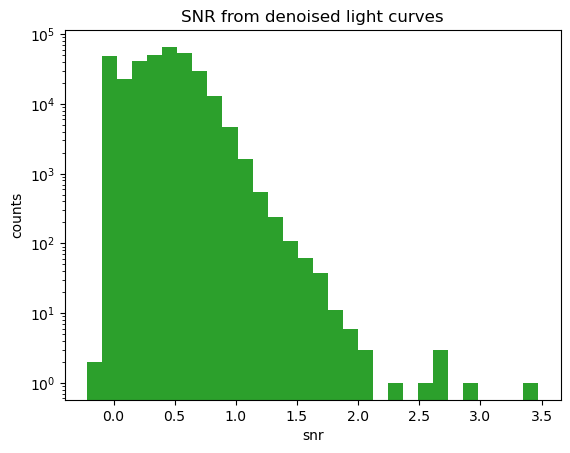

In [19]:
plt.hist(nosats['snr_local_denoised'], bins=30)
plt.yscale('log')
plt.title('SNR from denoised light curves')
plt.xlabel('snr')
plt.ylabel('counts')
plt.show()

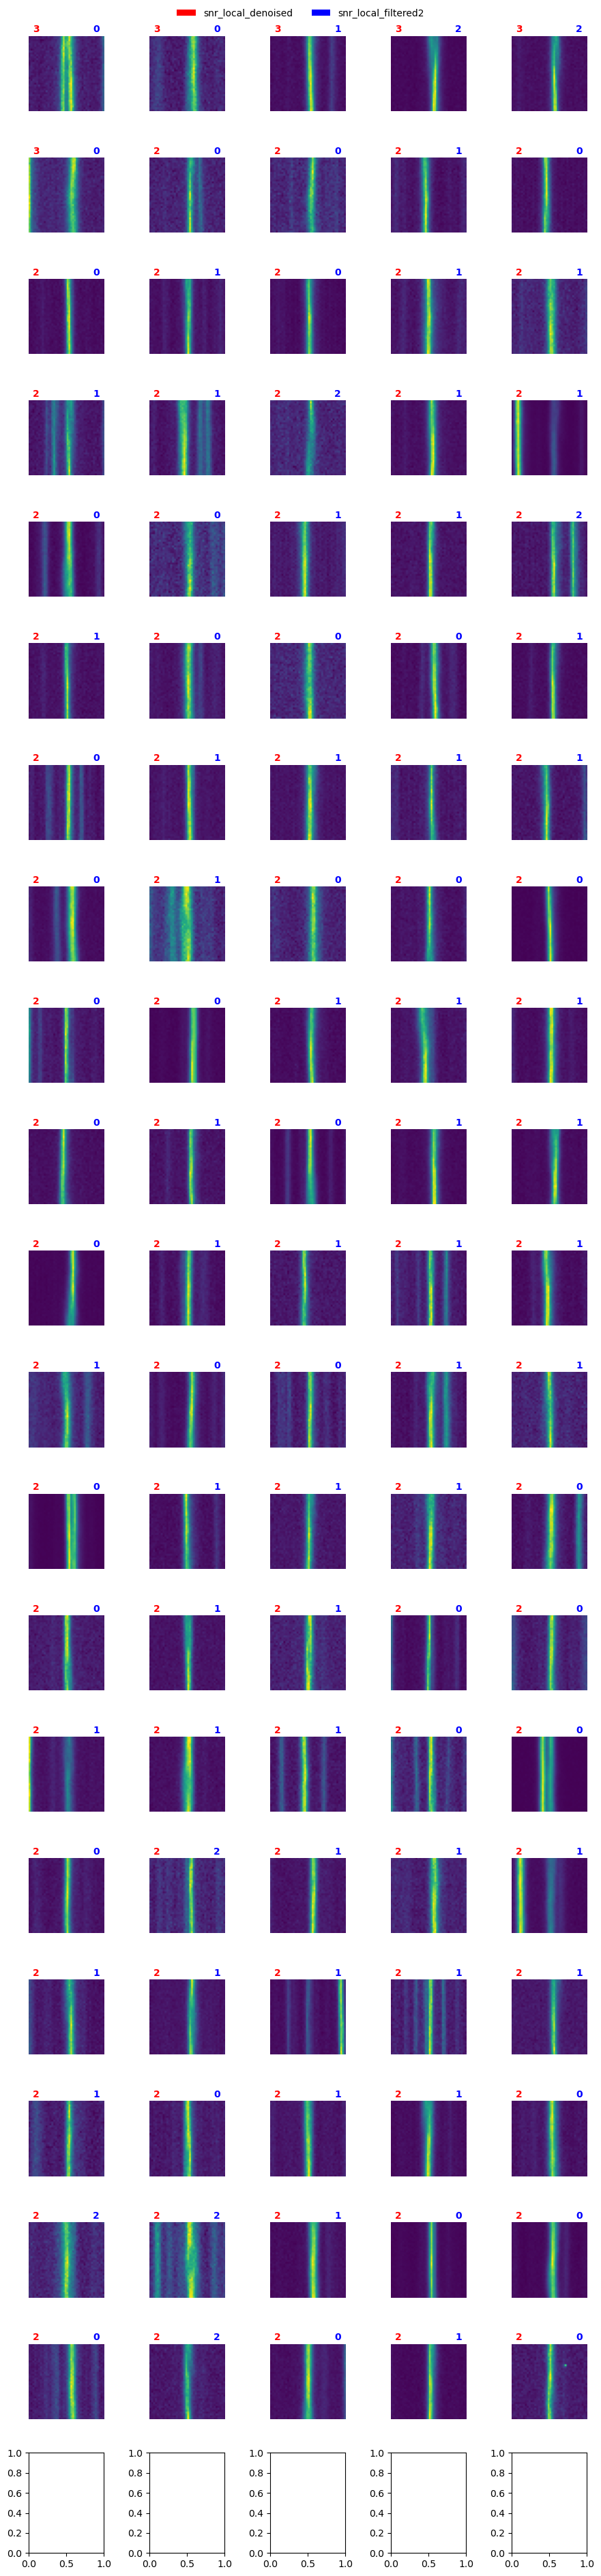

In [22]:
rff.inspect_df_w_stamp_color(last_final_df.sort_values('snr_local_denoised', ascending=False), 
                             titlecol=['snr_local_denoised', 'snr_local_filtered2'], imgsize=20)


In [223]:
# the_final_df.to_csv('/lustre/lrspec/ZTF_data/final_df_temp')

In [15]:
%matplotlib inline

In [26]:
import importlib

In [27]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

2139.0
1558.0
lightcurve_ztf_20221020148032_000686_zg_c16_x_0000_1_2139_1558_time_adjusted_concat_denoised
223.0
1462.0
lightcurve_ztf_20221020148032_000686_zg_c03_x_0000_3_0223_1462_time_adjusted_concat_denoised
2987.0
279.0
lightcurve_ztf_20221020148032_000686_zg_c03_x_0000_1_2987_0279_time_adjusted_concat_denoised
1344.0
2783.0
lightcurve_ztf_20221020148032_000686_zg_c11_x_0000_2_1344_2783_time_adjusted_concat_denoised
191.0
1932.0
lightcurve_ztf_20221020148032_000686_zg_c03_x_0000_2_0191_1932_time_adjusted_concat_denoised
2874.0
1035.0
lightcurve_ztf_20221020148032_000686_zg_c14_x_0000_3_2874_1035_time_adjusted_concat_denoised
536.0
1931.0
lightcurve_ztf_20221020294271_000449_zr_c16_x_0000_4_0536_1931_time_adjusted_concat_denoised
523.0
1638.0
lightcurve_ztf_20221020148032_000686_zg_c03_x_0000_1_0523_1638_time_adjusted_concat_denoised
2779.0
1597.0
lightcurve_ztf_20221020294271_000449_zr_c14_x_0000_4_2779_1597_time_adjusted_concat_denoised
536.0
1931.0
lightcurve_ztf_20221020294271

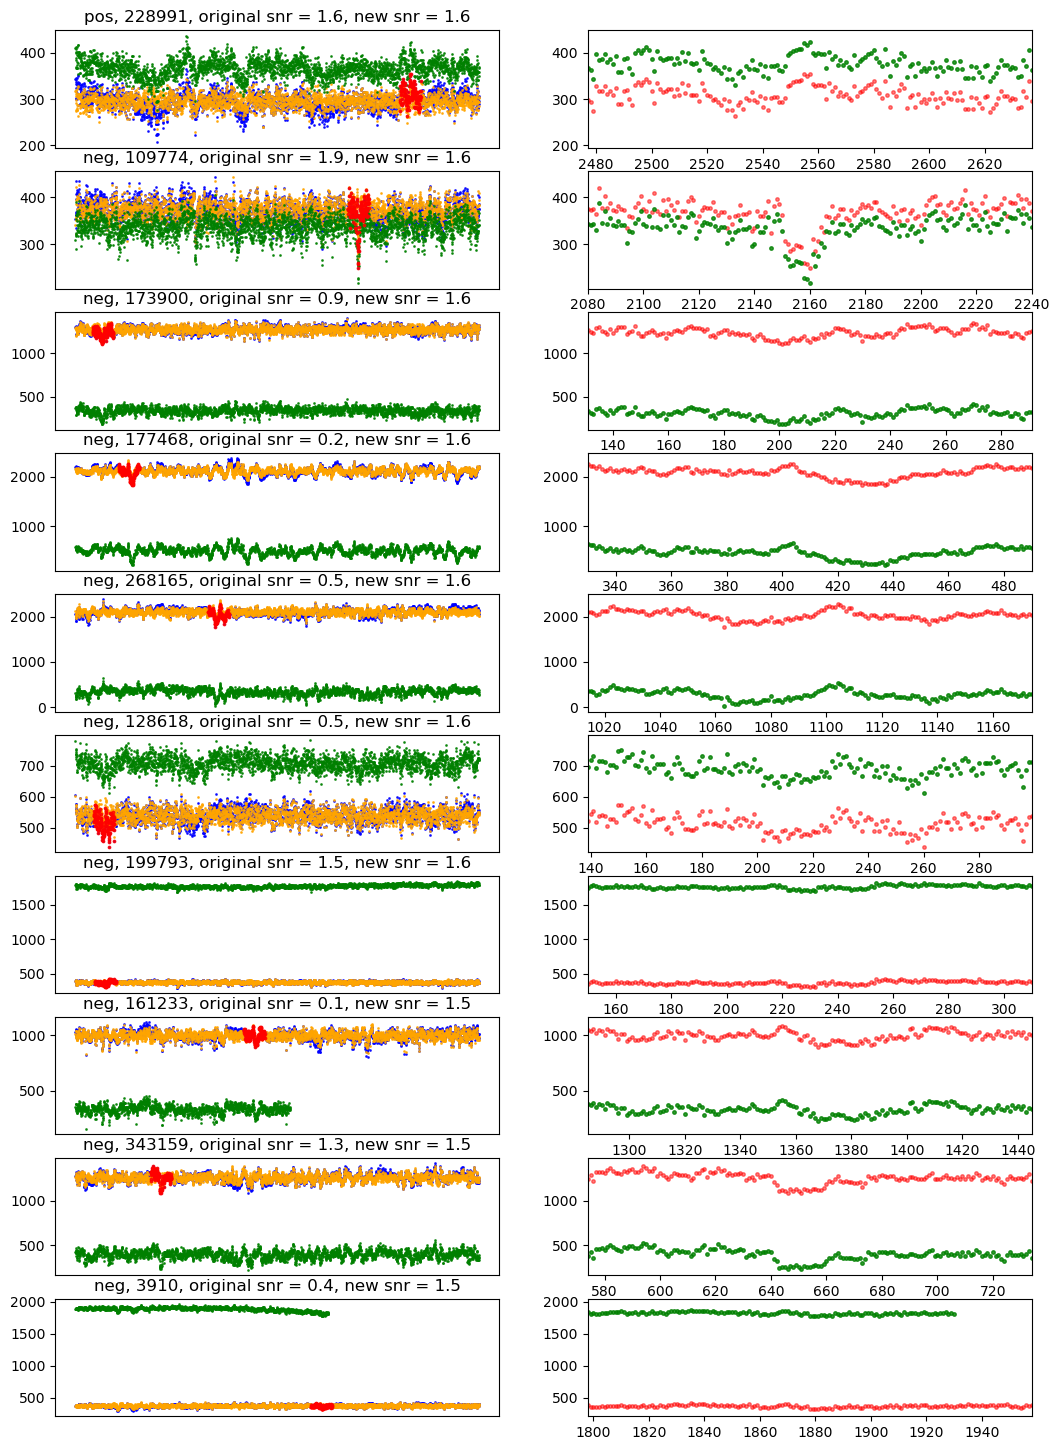

In [30]:
size = 160
# new = final_df_rfgood_filtered.loc[indices_to_plot]
# df = final_df_rfgood_filtered.loc[indices_to_plot]
df = last_final_df[-10:]
figrows = len(df)
fig, ax = plt.subplots(figrows, 2, figsize=(7 * 1.8, figrows * 1.8))

for i, index in enumerate(df.index[:figrows].values):
    # print(index)
    print(df.loc[index,'closest_x'])
    print(df.loc[index,'closest_y'])
    tot, maxols = rff.get_tot_csv(df, index)
    ax[i,0].plot(tot, '.', ms=2, alpha=.8, c='blue')
    tot_filt = rff.get_tot_csv_filtered_hap2(df, index)
    ax[i,0].plot(tot_filt, '.', ms=2, alpha=.8, c='orange')
    ax[i,0].set_title(str(df.loc[index, "real_type_local"])+", "+str(
        df.loc[index, "concat_index_copy"])+", original snr = "+f"{df.loc[index, 'snr_local_filtered2']:.1f}"+", new snr = "+f"{df.loc[index, 'snr_local_denoised']:.1f}"
                     )
    ax[i,0].set_xticks([])
    ax[i,1].plot(tot, '.', ms=5, alpha=.5, c='red')
    
    try:
        if str(df.loc[index, "real_type_local"])=='pos':
            range1 = np.max([int(df.loc[index, 'central_point_brightening_denoise']-size//2), 0])
            range2 = np.min([int(df.loc[index, 'central_point_brightening_denoise']+size//2-1), len(tot)-1])
            xes = np.linspace(range1, range2, range2-range1+1)
            # print(range1, range2, xes)
            # print(range1, range2, len(tot), len(tot[range1:range2+1]))
            # print(len(xes))
            # print(xes)
            ax[i,1].set_xlim(range1, range2+1)
            ax[i,0].scatter(xes,tot[range1:range2+1],  s=3, alpha=.8, c='red', zorder=10)
        elif str(df.loc[index, "real_type_local"])=='neg':
            
            range1 = np.max([int(df.loc[index, 'central_point_dimming_denoised']-size//2), 0])
            range2 = np.min([int(df.loc[index, 'central_point_dimming_denoised']+size//2-1), len(tot)-1])
            # print(range1, range2, len(tot), len(tot[range1:range2+1]), len(xes))
            xes = np.linspace(range1, range2, range2-range1+1)
            # print(range1, range2, xes)
            # print(len(xes))
            # print(xes)
            ax[i,1].set_xlim(range1, range2+1)
            ax[i,0].scatter(xes,tot[range1:range2+1],  s=3, alpha=.8, c='red', zorder=10)
            
            # xes = np.linspace(df.loc[index, 'central_point_dimming_filtere']-size//2,df.loc[index, 'central_point_dimming_filtere']+size//2-1,2*(size//2))
            # # print(len(xes))
            # # print(xes)
            # ax[i,1].set_xlim(df.loc[index, 'central_point_dimming_filtere']-size//2, df.loc[index, 'central_point_dimming_filtere']+size//2)
            # ax[i,0].scatter(xes,tot[int(df.loc[index, 'central_point_dimming_filtere'])-size//2:int(df.loc[index, 'central_point_dimming_filtere'])+size//2],  s=15, alpha=.8, c='red', zorder=10)
    except TypeError:
        pass
    try:
        tot_denoised = rff.get_tot_denoised(df, index)
        ax[i,0].plot(tot_denoised, '.', ms=2, alpha=.8, c='green')
        ax[i,1].plot(tot_denoised, '.', ms=5, alpha=.8, c='green')
    except:
        print("couldnt get tot denoised")
plt.show()

In [189]:
import numpy as np
import pandas as pd
import os
from sklearn.decomposition import PCA
from scipy.fft import fft, ifft, fftfreq

predictions = '/lustre/lrspec/ZTF_data/random_forest_training/predictions_w_fname.csv'



def apply_fft_lowpass(data, fs=1, fc=0.0003):
    """
    data: 1D numpy array (single sensor)
    fs: sampling frequency
    fc: cutoff frequency
    """
    n = len(data)
    fft_vals = fft(data)
    freqs = fftfreq(n, d=1)
    
    # Create a mask: keep frequencies where |freq| <= fc
    mask = np.abs(freqs) <= fc
    
    # Apply mask (zero out high frequencies)
    fft_vals_filtered = fft_vals * mask
    
    # Transform back to time domain (real part)
    return np.real(ifft(fft_vals_filtered))


original_direc = '/lustre/lrspec/ZTF_data/lightcurves/1020_time_concat/'
new_direc = '/lustre/lrspec/ZTF_data/lightcurves/1020_time_concat_denoised_rf/'

all_filestarts = np.load('/home/3155/all_filestarts.npy')
#need to do it per-chip
for filestart in all_filestarts:
    filelist = [file for file in os.listdir(original_direc) if file.startswith(filestart)]
    lc_dict = {
        file: np.load(os.path.join(original_direc, file))
        for file in filelist if np.sum(predictions[predictions['filename_new']==file]['binary'].values)<1
    }
    df = pd.DataFrame.from_dict(lc_dict, orient='index')  # rows=filenames, cols=time points
    

TypeError: string indices must be integers, not 'str'

In [196]:
lc_dict = {
        file: np.load(os.path.join(original_direc, file))
        for file in filelist if (np.sum(predictions[predictions['filename_new']==file]['binary'].values)<1)
    }

In [16]:
filename = 'lightcurve_ztf_20221020138241_000686_zi_c16_lightcurve_ztf_20221020138241_000686_zi_c16_x_0000_3_1116_1214_time_adjusted_concat_denoised'

In [17]:
path = '/lustre/lrspec/ZTF_data/lightcurves/1020_time_concat_denoised_rf_again/'

In [19]:
%matplotlib inline

In [24]:
last_final_df

,Unnamed: 0.10,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,...,noise_local_dimming_denoised,noise_global_dimming_denoised,local_average_outside_dimming_denoised,height_dimming_denoised,FWHM_dimming_denoised,signal_local_dimming_denoised,central_point_dimming_denoised,concat_index_copy,snr_local_denoised,central_point
0,0,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,0.0
231574,231574,231574,231574,231574,231574,231574,231574,231574,231574,85,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,231574,0.0,0.0
231592,231592,231592,231592,231592,231592,231592,231592,231592,231592,103,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,231592,0.0,0.0
231591,231591,231591,231591,231591,231591,231591,231591,231591,231591,102,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,231591,0.0,0.0
231590,231590,231590,231590,231590,231590,231590,231590,231590,231590,101,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,231590,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
231677,231677,231677,231677,231677,231677,231677,231677,231677,231677,37,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,231677,0.0,0.0
231676,231676,231676,231676,231676,231676,231676,231676,231676,231676,36,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,231676,0.0,0.0
231675,231675,231675,231675,231675,231675,231675,231675,231675,231675,35,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,231675,0.0,0.0
231674,231674,231674,231674,231674,231674,231674,231674,231674,231674,34,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,231674,0.0,0.0


In [26]:
concat_lil = concat_good[:100]

In [32]:
concat

,Unnamed: 0.10,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,...,central_point_brightening_denoise,snr_local_dimming_denoised,snr_global_dimming_denoised,noise_local_dimming_denoised,noise_global_dimming_denoised,local_average_outside_dimming_denoised,height_dimming_denoised,FWHM_dimming_denoised,signal_local_dimming_denoised,central_point_dimming_denoised
0,0,0,0,0,0,0,0,0,0,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,1,1,1,1,1,1,1,1,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2,2,2,2,2,2,2,2,2,2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,3,3,3,3,3,3,3,3,3,3,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,4,4,4,4,4,4,4,4,4,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
347419,347419,347419,347419,347419,347419,347419,347419,347419,347419,49,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
347420,347420,347420,347420,347420,347420,347420,347420,347420,347420,50,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
347421,347421,347421,347421,347421,347421,347421,347421,347421,347421,51,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
347422,347422,347422,347422,347422,347422,347422,347422,347422,347422,0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [40]:
'lightcurve_ztf_20221020138241_000686_zi_c16_lightcurve_ztf_20221020138241_000686_zi_c16_x_0000_3_1116_1214_time_adjusted_concat_denoised'[44:]

'lightcurve_ztf_20221020138241_000686_zi_c16_x_0000_3_1116_1214_time_adjusted_concat_denoised'

In [42]:
import os

In [44]:
directory = '/lustre/lrspec/ZTF_data/lightcurves/1020_time_concat_denoised_rf_again/'
files = [file for file in os.listdir(directory)]
for file in files:
    newfile = file[44:]
    os.rename(directory+file, directory+newfile)

In [45]:
rff.get_tot_denoised(concat, 104)

lightcurve_ztf_20221020163819_000640_zg_c12_x_0000_3_0246_1339_time_adjusted_concat_denoised


array([496.91115629, 470.54022561, 447.36265356, ..., 447.68955368,
       511.37031505, 466.24418175])

In [46]:
rff.get_tot_denoised(last_final_df,231674)

lightcurve_ztf_20221020148032_000686_zg_c07_x_0000_4_1985_0594_time_adjusted_concat_denoised


array([332.7774813 , 386.28617081, 363.60119999, ..., 401.64226315,
       421.85841169, 392.37857728])

In [27]:
import importlib

In [57]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [59]:
%matplotlib inline

In [41]:
len(rff.get_tot_csv(concat_good,concat_good.index[n])[0])

3080

In [62]:
df = rff.add_snr_both_denoised(concat_good[:10])

lightcurve_ztf_20221020141806_000686_zi_c11_x_0000_4_0919_0835_time_adjusted_concat_denoised
lightcurve_ztf_20221020141806_000686_zi_c11_x_0000_4_1246_1191_time_adjusted_concat_denoised
lightcurve_ztf_20221020148032_000686_zg_c14_x_0000_1_1069_1803_time_adjusted_concat_denoised


In [63]:
df

,Unnamed: 0.10,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,...,central_point_brightening_denoise,snr_local_dimming_denoised,snr_global_dimming_denoised,noise_local_dimming_denoised,noise_global_dimming_denoised,local_average_outside_dimming_denoised,height_dimming_denoised,FWHM_dimming_denoised,signal_local_dimming_denoised,central_point_dimming_denoised
0,0,0,0,0,0,0,0,0,0,0,...,697.0,0.097634,0.119836,211.498252,172.313005,574.058211,-262.954360,2.0,20.649366,703.0
1,1,1,1,1,1,1,1,1,1,1,...,1175.0,0.163383,0.147859,157.519775,174.057900,547.898898,-252.161251,3.0,25.736019,1168.0
2,2,2,2,2,2,2,2,2,2,2,...,2087.0,0.044367,0.035578,136.544338,170.276620,600.103755,-36.699783,1.0,6.058035,2082.0
3,3,3,3,3,3,3,3,3,3,3,...,2467.0,0.088891,0.094558,181.918712,171.016256,603.029128,-164.977715,2.0,16.171015,2461.0
4,4,4,4,4,4,4,4,4,4,4,...,2572.0,0.193704,0.186482,164.263000,170.624386,640.590673,-508.411280,2.0,31.818422,2578.0
5,5,5,5,5,5,5,5,5,5,5,...,2932.0,0.157204,0.131766,143.986306,171.783169,681.574420,-306.446773,2.0,22.635267,2942.0
6,6,6,6,6,6,6,6,6,6,6,...,2224.0,0.517154,0.485959,38.534592,41.008194,601.406119,-102.250840,5.0,19.928308,2229.0
7,7,7,7,7,7,7,7,7,7,7,...,281.0,0.422908,0.417901,40.469312,40.954174,575.858630,-93.446257,4.0,17.114799,291.0
8,8,8,8,8,8,8,8,8,8,0,...,1866.0,0.269889,0.281966,248.680249,238.028861,694.776588,-665.403990,9.0,67.116148,1852.0
9,9,9,9,9,9,9,9,9,9,1,...,2591.0,0.196580,0.206267,242.548721,231.157496,698.548811,-367.659267,9.0,47.680202,2581.0


lightcurve_ztf_20221020297847_000449_zr_c13_x_0000_3_0956_1627_time_adjusted_concat_denoised


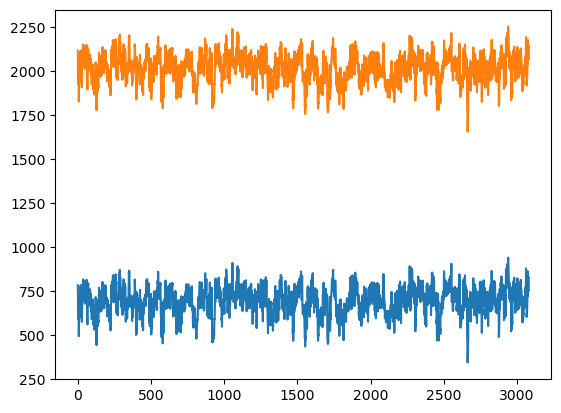

In [61]:
n=30

plt.plot(rff.get_tot_denoised(concat_good,concat_good.index[n]))
plt.plot(rff.get_tot_csv(concat_good,concat_good.index[n])[0])
plt.show()

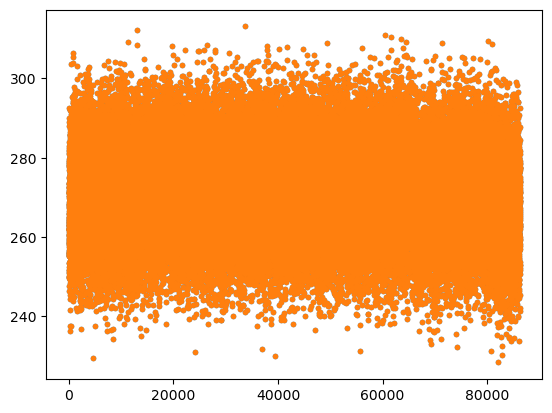

In [20]:
plt.plot(pd.read_csv(path+filename),'.')
plt.show()

In [24]:
import os

In [25]:
predictions = pd.read_csv('/lustre/lrspec/ZTF_data/random_forest_training/predictions_w_fname.csv')

def apply_fft_lowpass_series(s, fs=1, fc=0.0003):
    """
    s: pandas Series (single light curve), index = time points / columns
    Returns a Series with the same index/name.
    """
    data = s.values
    n = len(data)
    fft_vals = fft(data)
    freqs = fftfreq(n, d=1)
    mask = np.abs(freqs) <= fc
    fft_vals_filtered = fft_vals * mask
    filtered = np.real(ifft(fft_vals_filtered))
    return pd.Series(filtered, index=s.index, name=s.name)

original_direc = '/lustre/lrspec/ZTF_data/lightcurves/1020_time_concat/'
new_direc = '/lustre/lrspec/ZTF_data/lightcurves/1020_time_concat_denoised_rf_again/'
all_filestarts = np.load('/home/3155/all_filestarts.npy')

for filestart in all_filestarts:
    filelist = [file for file in os.listdir(original_direc) if file.startswith(filestart)]

    lc_dict = {
        file: np.load(os.path.join(original_direc, file))
        for file in filelist
        if np.sum(predictions[predictions['filename_new'] == file]['binary'].values) < 1
    }

    # rows = filenames, cols = time points; index carries filenames explicitly
    df = pd.DataFrame.from_dict(lc_dict, orient='index')

    print(filestart, flush=True)
    print('shape df: ', df.shape, flush=True)

    if df.empty:
        print('  no non-binary files found, skipping', flush=True)
        continue

    # sanity check: no unexpected NaNs from unequal-length light curves
    n_nan_rows = df.isna().any(axis=1).sum()
    if n_nan_rows > 0:
        print(f'  WARNING: {n_nan_rows} rows contain NaNs (unequal-length curves?)', flush=True)

    # --- lowpass filter, row by row, staying in DataFrame form ---
    # df.apply(axis=1) passes each row as a Series (index=time cols, name=filename)
    # and returns a Series per row, so the filename label travels with the data.
    df_lowpass = df.apply(apply_fft_lowpass_series, axis=1, fs=1, fc=0.0003)
    df_lowpass.index = df.index  # explicit, but should already match
    df_lowpass.columns = df.columns

    assert df_lowpass.index.equals(df.index), "lowpass output index mismatch!"

    # --- PCA on lowpassed data ---
    # rows=filenames, cols=time -> PCA expects samples as rows, so this matches (X = files x time)
    X_df = df_lowpass
    X_centered_df = X_df - X_df.mean(axis=0)

    Xdo = X_centered_df.values  # PCA needs a bare array, but we keep the index/columns alongside

    pca = PCA()
    pca.fit(Xdo)

    k = 10
    pca_noise = PCA(n_components=k)
    pca_noise.fit(Xdo)
    common_noise = pca_noise.inverse_transform(pca_noise.transform(Xdo))

    # rebuild common_noise as a DataFrame with the SAME index/columns as X_centered_df
    common_noise_df = pd.DataFrame(
        common_noise, index=X_centered_df.index, columns=X_centered_df.columns
    )

    # subtract using DataFrame arithmetic -> pandas aligns on index/columns automatically
    # and would raise/produce NaNs (visibly) rather than silently misaligning positionally
    df_denoised = df - common_noise_df

    assert df_denoised.index.equals(df.index), "denoised output index mismatch!"
    print('shape df_denoised: ', df_denoised.shape, flush=True)

    # df_denoised.to_csv(f'/lustre/lrspec/ZTF_data/df_denoised_temp_{filestart}.csv')
    break
    # os.makedirs(new_direc, exist_ok=True)
    # for fname, row in df_denoised.iterrows():
        # namespace with filestart to avoid collisions across groups after truncating '.npy'
        # out_name = f'{filestart}_{fname[:-4]}_denoised'
        # row.to_csv(os.path.join(new_direc, out_name), header=False, index=False)

lightcurve_ztf_20221020138241_000686_zi_c09
shape df:  (308, 86240)
shape df_denoised:  (308, 86240)


In [29]:
X_centered_df

,0,1,2,3,4,5,6,7,8,9,...,86230,86231,86232,86233,86234,86235,86236,86237,86238,86239
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_4_0999_2857_time_adjusted_concat.npy,-280.673662,-280.674390,-280.675120,-280.675851,-280.676585,-280.677320,-280.678057,-280.678796,-280.679537,-280.680280,...,-280.666481,-280.667191,-280.667902,-280.668616,-280.669331,-280.670049,-280.670768,-280.671488,-280.672211,-280.672935
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_3_0891_2120_time_adjusted_concat.npy,-266.639874,-266.641443,-266.643013,-266.644583,-266.646155,-266.647726,-266.649299,-266.650871,-266.652445,-266.654019,...,-266.624214,-266.625777,-266.627341,-266.628905,-266.630470,-266.632036,-266.633602,-266.635169,-266.636737,-266.638305
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_2225_1757_time_adjusted_concat.npy,-163.160396,-163.159709,-163.159023,-163.158336,-163.157650,-163.156964,-163.156277,-163.155591,-163.154905,-163.154219,...,-163.167265,-163.166578,-163.165891,-163.165204,-163.164517,-163.163830,-163.163143,-163.162456,-163.161769,-163.161083
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_2548_1441_time_adjusted_concat.npy,516.727277,516.732795,516.738317,516.743843,516.749374,516.754909,516.760449,516.765993,516.771541,516.777094,...,516.672346,516.677819,516.683296,516.688778,516.694265,516.699756,516.705251,516.710751,516.716255,516.721764
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_3_2630_1977_time_adjusted_concat.npy,985.309104,985.302949,985.296801,985.290661,985.284528,985.278402,985.272283,985.266172,985.260068,985.253972,...,985.371048,985.364821,985.358602,985.352390,985.346185,985.339986,985.333796,985.327612,985.321435,985.315266
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_2_1648_2219_time_adjusted_concat.npy,-189.485154,-189.487616,-189.490083,-189.492554,-189.495029,-189.497509,-189.499992,-189.502481,-189.504973,-189.507470,...,-189.460768,-189.463187,-189.465611,-189.468039,-189.470471,-189.472907,-189.475348,-189.477793,-189.480242,-189.482696
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_3_0317_2664_time_adjusted_concat.npy,-283.231128,-283.229816,-283.228510,-283.227210,-283.225914,-283.224624,-283.223340,-283.222060,-283.220786,-283.219518,...,-283.244537,-283.243172,-283.241813,-283.240458,-283.239109,-283.237766,-283.236427,-283.235094,-283.233767,-283.232445
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_1201_1459_time_adjusted_concat.npy,1545.716002,1545.727185,1545.738381,1545.749590,1545.760811,1545.772045,1545.783292,1545.794552,1545.805825,1545.817110,...,1545.604886,1545.615939,1545.627005,1545.638084,1545.649176,1545.660282,1545.671400,1545.682531,1545.693675,1545.704832
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_4_3029_1435_time_adjusted_concat.npy,-184.121118,-184.118482,-184.115844,-184.113206,-184.110565,-184.107924,-184.105280,-184.102636,-184.099990,-184.097342,...,-184.147396,-184.144775,-184.142152,-184.139528,-184.136902,-184.134275,-184.131647,-184.129016,-184.126385,-184.123752


In [28]:
df_lowpass

,0,1,2,3,4,5,6,7,8,9,...,86230,86231,86232,86233,86234,86235,86236,86237,86238,86239
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_4_0999_2857_time_adjusted_concat.npy,80.757379,80.757566,80.757753,80.757938,80.758122,80.758304,80.758485,80.758665,80.758843,80.759020,...,80.755428,80.755629,80.755829,80.756027,80.756224,80.756420,80.756614,80.756807,80.756999,80.757190
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_3_0891_2120_time_adjusted_concat.npy,94.791167,94.790513,94.789860,94.789206,94.788552,94.787898,94.787244,94.786590,94.785935,94.785281,...,94.797695,94.797043,94.796390,94.795738,94.795085,94.794432,94.793780,94.793127,94.792473,94.791820
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_2225_1757_time_adjusted_concat.npy,198.270645,198.272247,198.273850,198.275453,198.277057,198.278661,198.280265,198.281870,198.283475,198.285081,...,198.254644,198.256242,198.257841,198.259440,198.261039,198.262639,198.264239,198.265840,198.267441,198.269043
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_2548_1441_time_adjusted_concat.npy,878.158318,878.164751,878.171189,878.177632,878.184081,878.190533,878.196991,878.203454,878.209921,878.216394,...,878.094255,878.100639,878.107028,878.113422,878.119820,878.126224,878.132633,878.139047,878.145466,878.151889
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_3_2630_1977_time_adjusted_concat.npy,1346.740144,1346.734905,1346.729674,1346.724450,1346.719234,1346.714026,1346.708826,1346.703633,1346.698449,1346.693272,...,1346.792957,1346.787641,1346.782333,1346.777033,1346.771740,1346.766455,1346.761178,1346.755908,1346.750646,1346.745391
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_2_1648_2219_time_adjusted_concat.npy,171.945886,171.944340,171.942789,171.941235,171.939677,171.938116,171.936550,171.934981,171.933407,171.931830,...,171.961141,171.959633,171.958121,171.956605,171.955085,171.953561,171.952034,171.950503,171.948968,171.947429
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_3_0317_2664_time_adjusted_concat.npy,78.199912,78.202140,78.204362,78.206580,78.208792,78.211000,78.213203,78.215401,78.217594,78.219782,...,78.177372,78.179648,78.181919,78.184185,78.186446,78.188703,78.190955,78.193201,78.195443,78.197680
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_1201_1459_time_adjusted_concat.npy,1907.147043,1907.159141,1907.171253,1907.183379,1907.195518,1907.207670,1907.219835,1907.232014,1907.244205,1907.256410,...,1907.026795,1907.038759,1907.050736,1907.062727,1907.074732,1907.086750,1907.098782,1907.110827,1907.122885,1907.134957
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_4_3029_1435_time_adjusted_concat.npy,177.309923,177.313475,177.317028,177.320584,177.324141,177.327701,177.331262,177.334825,177.338390,177.341958,...,177.274513,177.278045,177.281579,177.285115,177.288653,177.292193,177.295735,177.299279,177.302825,177.306373


In [26]:
df_denoised

,0,1,2,3,4,5,6,7,8,9,...,86230,86231,86232,86233,86234,86235,86236,86237,86238,86239
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_4_0999_2857_time_adjusted_concat.npy,360.295261,353.572082,382.654689,384.986318,375.154249,369.545293,359.329203,363.222351,358.777591,346.029347,...,367.852033,368.486793,357.090500,350.187720,350.305462,387.335236,350.802219,348.777960,365.612463,342.342977
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_3_0891_2120_time_adjusted_concat.npy,375.465028,370.988244,343.991883,361.751198,371.702453,362.849569,370.094783,352.568711,363.008306,344.995020,...,348.061193,353.588228,340.264357,350.960840,344.145300,367.277528,346.838924,383.118062,364.199584,376.193245
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_2225_1757_time_adjusted_concat.npy,385.906893,382.321402,384.404183,382.885354,367.443062,353.266668,352.866838,378.463955,359.208638,366.336026,...,359.528851,363.391234,365.995239,374.482055,355.699400,339.962885,338.912862,356.875975,361.928412,349.939832
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_2548_1441_time_adjusted_concat.npy,317.417126,362.413613,352.432259,369.280985,370.398634,394.069692,375.959990,348.675304,369.306391,382.317181,...,386.297916,355.772833,355.766978,371.727128,376.443751,338.564307,308.735525,331.045112,369.267117,370.121142
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_3_2630_1977_time_adjusted_concat.npy,318.731661,338.880780,375.519399,367.682798,360.876226,429.080883,426.351092,405.584434,335.484890,292.041228,...,314.169880,365.624059,344.347647,303.624945,338.865011,346.442845,377.130785,328.806884,385.429760,386.239280
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_2_1648_2219_time_adjusted_concat.npy,343.990776,357.077534,360.668826,338.139820,319.081870,357.557278,347.172627,337.263198,380.525708,344.094433,...,386.026833,382.918651,371.110047,391.945062,350.246266,382.684968,404.029694,396.935916,393.393074,383.939177
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_3_0317_2664_time_adjusted_concat.npy,371.355880,380.593337,372.614110,373.003862,377.312687,390.433101,370.992074,367.348020,361.813483,380.254721,...,386.305572,363.739522,363.276977,350.980348,374.518623,353.485768,352.704399,363.046082,368.908828,371.071034
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_1_1201_1459_time_adjusted_concat.npy,391.943870,339.744240,378.300099,387.178586,332.080751,309.332155,339.816466,321.067008,324.198649,270.828212,...,337.922864,365.652961,412.932614,344.781234,332.590909,387.021185,431.110515,413.213025,365.422220,438.003970
lightcurve_ztf_20221020138241_000686_zi_c09_x_0000_4_3029_1435_time_adjusted_concat.npy,377.949806,345.135798,362.284101,369.906022,332.543706,376.524910,371.025829,350.067123,372.294452,367.900549,...,356.403255,348.406172,370.459717,353.824359,367.367147,343.855355,357.378734,361.852629,360.237184,374.658497
